In [28]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [29]:
# Load the raw dataset

df = pd.read_csv("complaints.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (95623, 15)


In [30]:
# Display all column names

print("Column Names:")
for column in df.columns:
    print(column)

Column Names:
Date received
Product
Sub-product
Issue
Sub-issue
Company public response
Company
State
ZIP code
Tags
Submitted via
Date sent to company
Company response to consumer
Timely response?
Complaint ID


In [31]:
# Display first 10 rows

df.head(10)

,Date received,Product,Sub-product,Issue,Sub-issue,Company public response,Company,State,ZIP code,Tags,Submitted via,Date sent to company,Company response to consumer,Timely response?,Complaint ID
0,2024-01-01T14:09:58.000Z,"Money transfer, virtual currency, or money ser...",Virtual currency,Fraud or scam,NaN,NaN,"Blockchain.com, Inc.",NaN,XXXXX,NaN,Web,2024-01-05T18:48:27.000Z,Closed with explanation,Yes,8086664
1,2024-01-01T15:46:52.000Z,"Money transfer, virtual currency, or money ser...",Mobile or digital wallet,Trouble accessing funds in your mobile or digi...,NaN,NaN,"Block, Inc.",TX,77077,NaN,Web,2024-01-01T16:14:51.000Z,Closed with explanation,Yes,8086481
2,2024-01-02T12:28:53.000Z,"Money transfer, virtual currency, or money ser...",Domestic (US) money transfer,Money was not available when promised,NaN,NaN,JPMORGAN CHASE & CO.,AZ,85268,NaN,Web,2024-01-02T13:09:10.000Z,Closed with explanation,Yes,8091254
3,2024-01-01T18:46:11.000Z,"Money transfer, virtual currency, or money ser...",Mobile or digital wallet,Fraud or scam,NaN,NaN,Chime Financial Inc,OH,44060,NaN,Web,2024-01-01T18:59:26.000Z,Closed with explanation,Yes,8088927
4,2024-01-02T16:28:15.000Z,"Money transfer, virtual currency, or money ser...",Mobile or digital wallet,Trouble accessing funds in your mobile or digi...,NaN,NaN,"Block, Inc.",IL,60085,NaN,Phone,2024-01-02T16:51:59.000Z,Closed with explanation,Yes,8090435
5,2024-01-01T04:50:06.000Z,"Money transfer, virtual currency, or money ser...","Money order, traveler's check or cashier's check",Lost or stolen money order,NaN,Company has responded to the consumer and the ...,"BANK OF AMERICA, NATIONAL ASSOCIATION",NaN,119XX,Older American,Web,2024-01-01T05:39:36.000Z,Closed with explanation,Yes,8086928
6,2024-01-01T12:13:22.000Z,"Money transfer, virtual currency, or money ser...",Domestic (US) money transfer,Other transaction problem,NaN,NaN,"CLGF Holdco 1, LLC",CA,94103,NaN,Web,2024-01-01T12:25:01.000Z,Closed with explanation,Yes,8086742
7,2024-01-01T21:58:53.000Z,"Money transfer, virtual currency, or money ser...",Virtual currency,Fraud or scam,NaN,NaN,"Coinbase, Inc.",MD,21244,NaN,Web,2024-01-01T22:14:05.000Z,Closed with explanation,Yes,8088148
8,2024-01-01T15:53:23.000Z,"Money transfer, virtual currency, or money ser...",Domestic (US) money transfer,Money was not available when promised,NaN,Company has responded to the consumer and the ...,U.S. BANCORP,NC,288XX,NaN,Web,2024-01-01T16:01:56.000Z,Closed with explanation,Yes,8088541
9,2024-01-01T23:08:50.000Z,"Money transfer, virtual currency, or money ser...",Mobile or digital wallet,Fraud or scam,NaN,NaN,"Paypal Holdings, Inc",AZ,85120,Servicemember,Web,2024-01-01T23:16:04.000Z,Closed with explanation,Yes,8087984


In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 95623 entries, 0 to 95622
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Date received                 95623 non-null  str    
 1   Product                       95623 non-null  str    
 2   Sub-product                   95623 non-null  str    
 3   Issue                         95623 non-null  str    
 4   Sub-issue                     0 non-null      float64
 5   Company public response       7747 non-null   str    
 6   Company                       95623 non-null  str    
 7   State                         94395 non-null  str    
 8   ZIP code                      95623 non-null  str    
 9   Tags                          8656 non-null   str    
 10  Submitted via                 95623 non-null  str    
 11  Date sent to company          95623 non-null  str    
 12  Company response to consumer  95623 non-null  str    
 13  Timely respo

In [33]:
# Check missing values in each column

missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_report = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

missing_report = missing_report.sort_values(
    by='Missing Percentage',
    ascending=False
)

print("Missing Value Analysis:")
display(missing_report)

Missing Value Analysis:


,Missing Values,Missing Percentage
Sub-issue,95623,100.000000
Company public response,87876,91.898393
Tags,86967,90.947785
State,1228,1.284210
Product,0,0.000000
Sub-product,0,0.000000
Date received,0,0.000000
Company,0,0.000000
Issue,0,0.000000
ZIP code,0,0.000000


In [34]:
# Check duplicate records

print("Total duplicate rows:", df.duplicated().sum())

print("Duplicate Complaint IDs:",
      df['Complaint ID'].duplicated().sum())

print("Unique Complaint IDs:",
      df['Complaint ID'].nunique())

Total duplicate rows: 0
Duplicate Complaint IDs: 0
Unique Complaint IDs: 95623


In [35]:
# Create a working copy of the original dataset

df_clean = df.copy()

# Convert date columns into datetime format

df_clean['Date received'] = pd.to_datetime(
    df_clean['Date received'],
    errors='coerce'
)

df_clean['Date sent to company'] = pd.to_datetime(
    df_clean['Date sent to company'],
    errors='coerce'
)

# Display updated data types

print("Updated Data Types:")
print(df_clean[['Date received',
                'Date sent to company']].dtypes)

# Display date range

print("\nDate Received Range:")
print("Start:", df_clean['Date received'].min())
print("End:", df_clean['Date received'].max())

print("\nDate Sent Range:")
print("Start:", df_clean['Date sent to company'].min())
print("End:", df_clean['Date sent to company'].max())

Updated Data Types:
Date received           datetime64[us, UTC]
Date sent to company    datetime64[us, UTC]
dtype: object

Date Received Range:
Start: 2024-01-01 04:50:06+00:00
End: 2025-12-31 23:55:37+00:00

Date Sent Range:
Start: 2024-01-01 05:39:36+00:00
End: 2026-07-09 17:43:00+00:00


In [36]:
# Calculate days between complaint receipt and sending to company

df_clean['Days to Company'] = (
    df_clean['Date sent to company'] -
    df_clean['Date received']
).dt.total_seconds() / (24 * 60 * 60)

# Display statistical summary

print("Forwarding Interval Statistics:")
print(df_clean['Days to Company'].describe())

# Check for negative intervals

print("\nNegative intervals:",
      (df_clean['Days to Company'] < 0).sum())

# Check missing intervals

print("Missing intervals:",
      df_clean['Days to Company'].isnull().sum())

Forwarding Interval Statistics:
count    95623.000000
mean         0.793332
std          5.465562
min          0.000972
25%          0.006898
50%          0.011366
75%          0.020220
max        283.152245
Name: Days to Company, dtype: float64

Negative intervals: 0
Missing intervals: 0


In [37]:
print(df["Date received"].dtype)

str


In [38]:
df["Date received"] = pd.to_datetime(
    df["Date received"],
    errors="coerce",
    utc=True
)

print(df["Date received"].dtype)

datetime64[us, UTC]


In [39]:
# Prepare monthly complaint data
monthly_data = df.groupby(
    df["Date received"].dt.to_period("M")
).size()

# Convert monthly index to timestamps for plotting
monthly_data.index = monthly_data.index.to_timestamp()

print(monthly_data)

Date received
2024-01-01     1089
2024-02-01     1125
2024-03-01     1244
2024-04-01     1072
2024-05-01     1116
2024-06-01     1039
2024-07-01     1114
2024-08-01     1327
2024-09-01     1112
2024-10-01     1183
2024-11-01     1203
2024-12-01     1548
2025-01-01    49359
2025-02-01     5905
2025-03-01     2820
2025-04-01     2288
2025-05-01     2404
2025-06-01     2193
2025-07-01     2555
2025-08-01     2596
2025-09-01     2237
2025-10-01     3941
2025-11-01     2323
2025-12-01     2830
Freq: MS, dtype: int64


C:\Users\Anshul Sharma\AppData\Local\Temp\ipykernel_7420\1231446813.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["Date received"].dt.to_period("M")


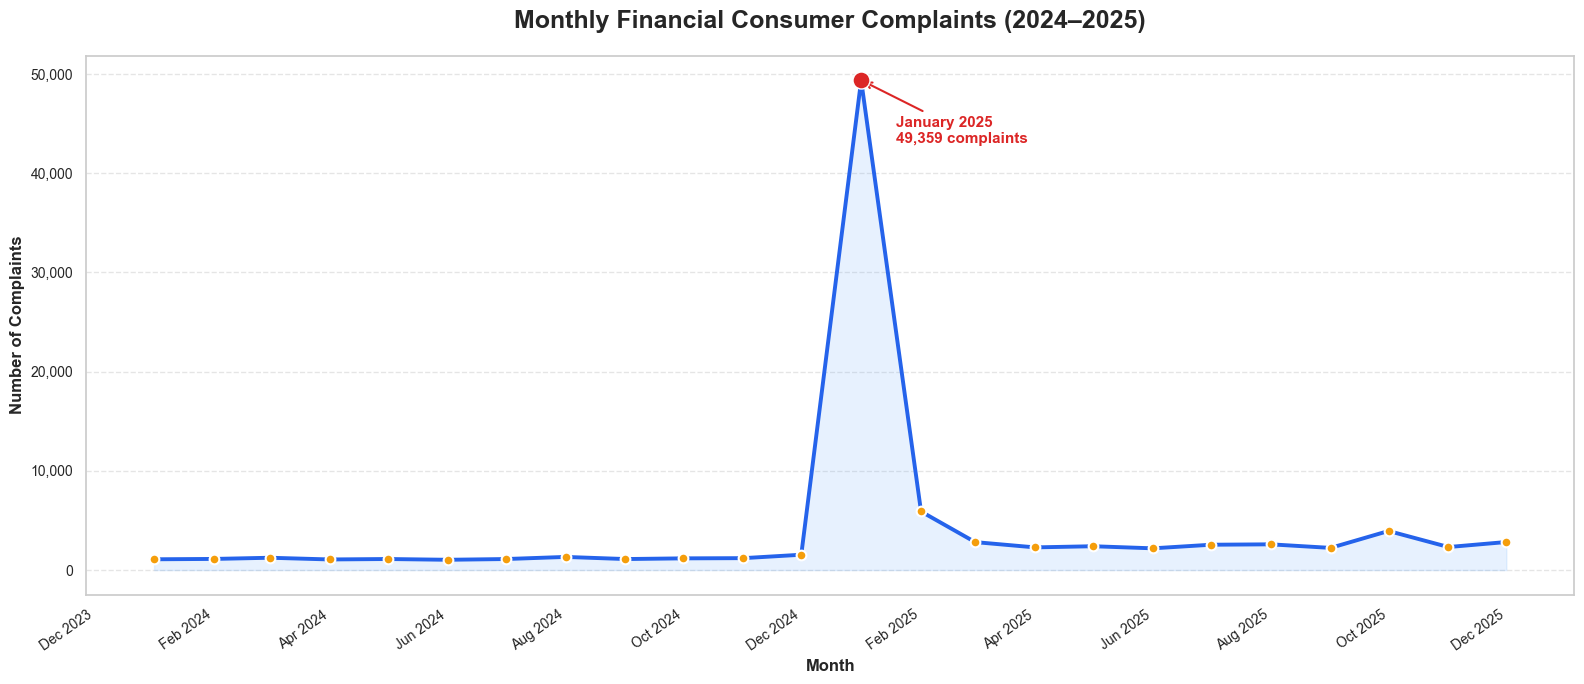

In [42]:

# Professional Monthly Complaint Trend Visualization

import matplotlib.dates as mdates

# Set visualization style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(16, 7))

# Create line plot
plt.plot(
    monthly_data.index,
    monthly_data.values,
    color="#2563EB",
    linewidth=2.8,
    marker="o",
    markersize=7,
    markerfacecolor="#F59E0B",
    markeredgecolor="white",
    markeredgewidth=1.5
)

# Fill area below the line
plt.fill_between(
    monthly_data.index,
    monthly_data.values,
    color="#60A5FA",
    alpha=0.15
)

# Identify highest month
peak_date = monthly_data.idxmax()
peak_value = monthly_data.max()

# Highlight highest month
plt.scatter(
    peak_date,
    peak_value,
    color="#DC2626",
    s=150,
    zorder=5,
    edgecolor="white"
)

# Annotate peak
plt.annotate(
    f"January 2025\n{peak_value:,} complaints",
    xy=(peak_date, peak_value),
    xytext=(25, -45),
    textcoords="offset points",
    fontsize=11,
    fontweight="bold",
    color="#DC2626",
    arrowprops=dict(
        arrowstyle="->",
        color="#DC2626",
        linewidth=1.5
    )
)

# Titles and labels
plt.title(
    "Monthly Financial Consumer Complaints (2024–2025)",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.xlabel("Month", fontsize=12, fontweight="bold")
plt.ylabel("Number of Complaints", fontsize=12, fontweight="bold")

# Format x-axis
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

# Format y-axis
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f"{int(x):,}")
)

plt.xticks(rotation=35, ha="right", fontsize=10)
plt.yticks(fontsize=10)

plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.grid(axis="x", visible=False)

plt.tight_layout()
plt.show()


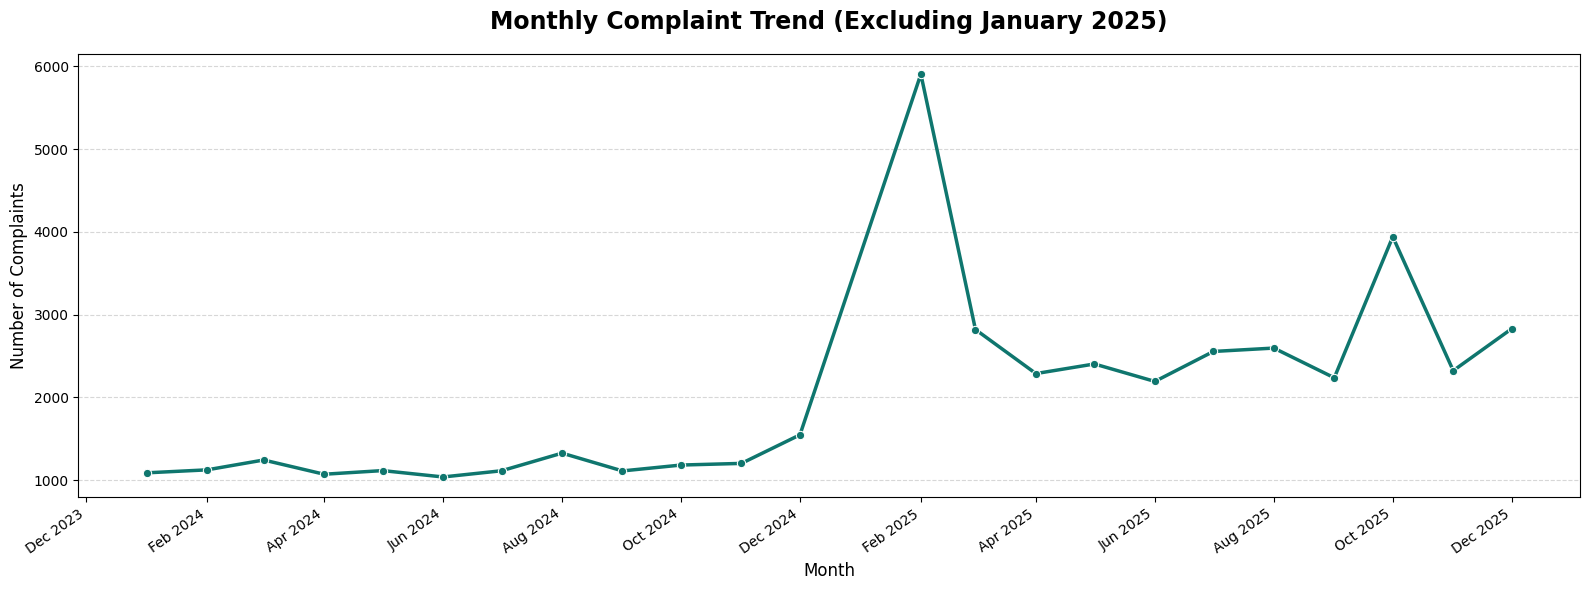

In [41]:

# Monthly trend excluding January 2025 for visual comparison

monthly_without_peak = monthly_data[
    monthly_data.index != pd.Timestamp("2025-01-01")
]

plt.figure(figsize=(16, 6))

sns.lineplot(
    x=monthly_without_peak.index,
    y=monthly_without_peak.values,
    marker="o",
    linewidth=2.5,
    color="#0F766E"
)

plt.title(
    "Monthly Complaint Trend (Excluding January 2025)",
    fontsize=17,
    fontweight="bold",
    pad=18
)

plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Complaints", fontsize=12)

plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=2))
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


Top 10 Complaint Issues:


Issue
Other transaction problem                                   55117
Fraud or scam                                               15745
Unauthorized transactions or other transaction problem       7418
Trouble accessing funds in your mobile or digital wallet     4404
Money was not available when promised                        2938
Managing, opening, or closing your mobile wallet account     2531
Other service problem                                        2437
Confusing or missing disclosures                             2104
Unexpected or other fees                                      773
Wrong amount charged or received                              520
Name: count, dtype: int64

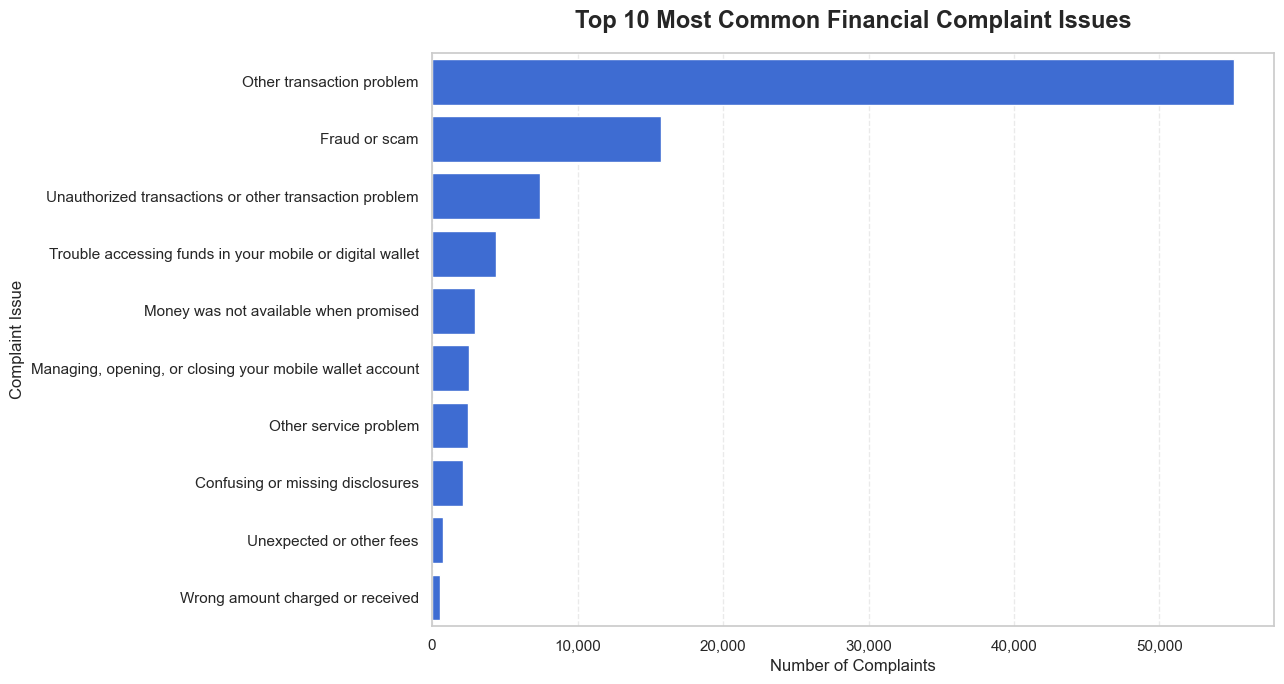

In [43]:

# Top 10 Most Common Financial Complaint Issues

top_issues = df_clean['Issue'].value_counts().head(10)

print("Top 10 Complaint Issues:")
display(top_issues)

# Professional visualization

plt.figure(figsize=(13, 7))

sns.barplot(
    x=top_issues.values,
    y=top_issues.index,
    color="#2563EB"
)

plt.title(
    "Top 10 Most Common Financial Complaint Issues",
    fontsize=17,
    fontweight="bold",
    pad=18
)

plt.xlabel("Number of Complaints", fontsize=12)
plt.ylabel("Complaint Issue", fontsize=12)

plt.gca().xaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, pos: f'{int(x):,}')
)

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.grid(axis="y", visible=False)

plt.tight_layout()
plt.show()


In [44]:
# Company response analysis

response_counts = df["Company response to consumer"].value_counts()

print("Company Response Distribution:")
print(response_counts)

print("\nResponse Percentages:")
print(
    (df["Company response to consumer"].value_counts(normalize=True) * 100)
    .round(2)
)

Company Response Distribution:
Company response to consumer
Closed with explanation            90650
Closed with monetary relief         2891
Closed with non-monetary relief     1936
Untimely response                    144
In progress                            2
Name: count, dtype: int64

Response Percentages:
Company response to consumer
Closed with explanation            94.80
Closed with monetary relief         3.02
Closed with non-monetary relief     2.02
Untimely response                   0.15
In progress                         0.00
Name: proportion, dtype: float64


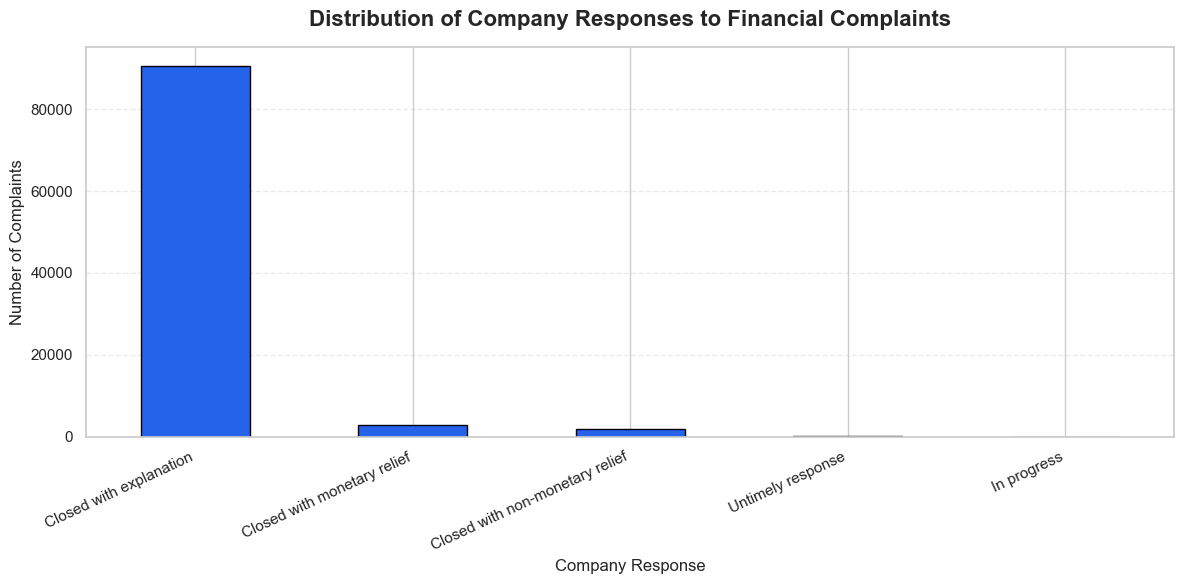

In [45]:
plt.figure(figsize=(12, 6))

response_counts.plot(
    kind="bar",
    color="#2563EB",
    edgecolor="black"
)

plt.title(
    "Distribution of Company Responses to Financial Complaints",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Company Response", fontsize=12)
plt.ylabel("Number of Complaints", fontsize=12)

plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [46]:
# Timely response analysis

timely_counts = df["Timely response?"].value_counts()

print("Timely Response Distribution:")
print(timely_counts)

print("\nTimely Response Percentages:")
print(
    (df["Timely response?"].value_counts(normalize=True) * 100).round(2)
)

Timely Response Distribution:
Timely response?
Yes    94457
No      1166
Name: count, dtype: int64

Timely Response Percentages:
Timely response?
Yes    98.78
No      1.22
Name: proportion, dtype: float64


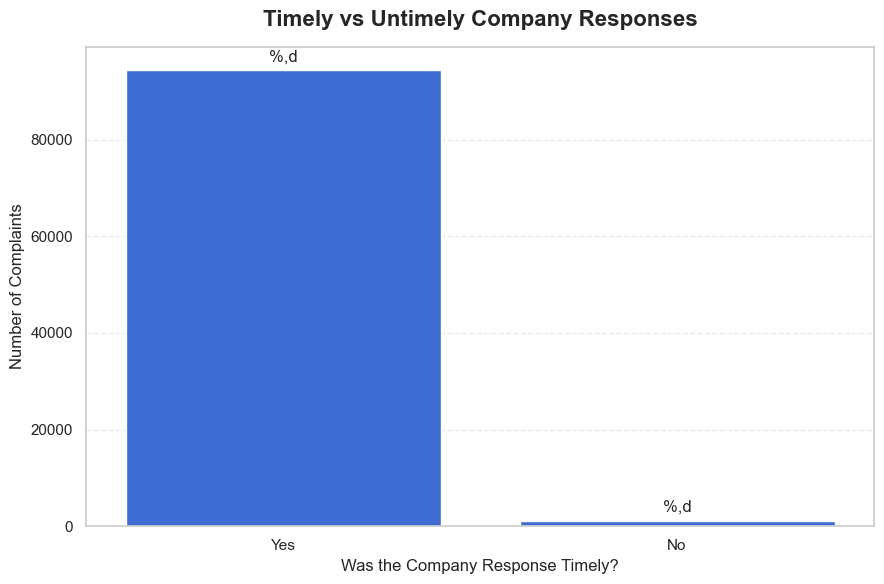

In [47]:
plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=timely_counts.index,
    y=timely_counts.values,
    color="#2563EB"
)

plt.title(
    "Timely vs Untimely Company Responses",
    fontsize=16,
    fontweight="bold",
    pad=15
)

plt.xlabel("Was the Company Response Timely?", fontsize=12)
plt.ylabel("Number of Complaints", fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt="%,d", padding=4)

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [48]:
# Check target variable distribution

print("Target variable: Timely response?")
print("\nUnique values:")
print(df["Timely response?"].unique())

print("\nValue counts:")
print(df["Timely response?"].value_counts())

print("\nPercentage distribution:")
print(df["Timely response?"].value_counts(normalize=True) * 100)

Target variable: Timely response?

Unique values:
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

Value counts:
Timely response?
Yes    94457
No      1166
Name: count, dtype: int64

Percentage distribution:
Timely response?
Yes    98.780628
No      1.219372
Name: proportion, dtype: float64


In [49]:

# Check unique values in selected categorical features

categorical_features = [
    'Product',
    'Sub-product',
    'Issue',
    'Company',
    'State',
    'Submitted via'
]

print("Unique values in categorical features:\n")

for column in categorical_features:
    print(f"{column}: {df[column].nunique()} unique values")


Unique values in categorical features:

Product: 1 unique values
Sub-product: 4 unique values
Issue: 15 unique values
Company: 517 unique values
State: 59 unique values
Submitted via: 4 unique values


In [50]:

# Step 20: Prepare dataset for Machine Learning

ml_df = df_clean.copy()

# Extract date-based features
ml_df['Year'] = ml_df['Date received'].dt.year
ml_df['Month'] = ml_df['Date received'].dt.month

# Select useful features and target
features = [
    'Sub-product',
    'Issue',
    'Company',
    'State',
    'Submitted via',
    'Days to Company',
    'Year',
    'Month'
]

target = 'Timely response?'

# Create final ML dataset
ml_df = ml_df[features + [target]].copy()

# Handle missing categorical values
categorical_columns = [
    'Sub-product',
    'Issue',
    'Company',
    'State',
    'Submitted via'
]

for column in categorical_columns:
    ml_df[column] = ml_df[column].fillna('Unknown')

# Remove rows with missing target or numerical features
ml_df = ml_df.dropna(
    subset=['Days to Company', 'Year', 'Month', target]
)

print("Machine Learning Dataset Created!")
print("Dataset shape:", ml_df.shape)

print("\nFirst 5 records:")
display(ml_df.head())

print("\nMissing values:")
print(ml_df.isnull().sum())


Machine Learning Dataset Created!
Dataset shape: (95623, 9)

First 5 records:


,Sub-product,Issue,Company,State,Submitted via,Days to Company,Year,Month,Timely response?
0,Virtual currency,Fraud or scam,"Blockchain.com, Inc.",Unknown,Web,4.193391,2024,1,Yes
1,Mobile or digital wallet,Trouble accessing funds in your mobile or digi...,"Block, Inc.",TX,Web,0.019433,2024,1,Yes
2,Domestic (US) money transfer,Money was not available when promised,JPMORGAN CHASE & CO.,AZ,Web,0.027975,2024,1,Yes
3,Mobile or digital wallet,Fraud or scam,Chime Financial Inc,OH,Web,0.009201,2024,1,Yes
4,Mobile or digital wallet,Trouble accessing funds in your mobile or digi...,"Block, Inc.",IL,Phone,0.016481,2024,1,Yes



Missing values:
Sub-product         0
Issue               0
Company             0
State               0
Submitted via       0
Days to Company     0
Year                0
Month               0
Timely response?    0
dtype: int64


In [51]:

from sklearn.model_selection import train_test_split

# Separate input features and target
X = ml_df.drop('Timely response?', axis=1)
y = ml_df['Timely response?']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training and Testing Split Completed!")

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


Training and Testing Split Completed!

Training features: (76498, 8)
Testing features: (19125, 8)

Training target distribution:
Timely response?
Yes    75565
No       933
Name: count, dtype: int64

Testing target distribution:
Timely response?
Yes    18892
No       233
Name: count, dtype: int64


In [52]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Categorical and numerical columns
categorical_features = [
    'Sub-product',
    'Issue',
    'Company',
    'State',
    'Submitted via'
]

numerical_features = [
    'Days to Company',
    'Year',
    'Month'
]

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', StandardScaler(), numerical_features)
    ]
)

print("Preprocessing configuration created successfully!")


Preprocessing configuration created successfully!


In [53]:

# Fit preprocessing on training data and transform both sets
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

print("\nOriginal training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)


Preprocessing completed successfully!

Original training shape: (76498, 8)
Processed training shape: (76498, 570)

Original testing shape: (19125, 8)
Processed testing shape: (19125, 570)


In [54]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Logistic Regression model
lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

# Train the model
lr_model.fit(X_train_processed, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test_processed)

print("Logistic Regression Model Trained Successfully!")

# Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, lr_predictions))

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, lr_predictions))


Logistic Regression Model Trained Successfully!

Accuracy: 0.8609150326797386

Classification Report:
              precision    recall  f1-score   support

          No       0.07      0.91      0.14       233
         Yes       1.00      0.86      0.92     18892

    accuracy                           0.86     19125
   macro avg       0.54      0.89      0.53     19125
weighted avg       0.99      0.86      0.91     19125


Confusion Matrix:
[[  212    21]
 [ 2639 16253]]


In [55]:

# ============================================================
# MODEL 1: LOGISTIC REGRESSION - RESULT INTERPRETATION
# ============================================================

# Accuracy: 86.09%
# The model correctly classified approximately 86.09% of
# all complaints in the testing dataset.

# Recall for No: 91%
# Out of 233 complaints with an untimely response, the model
# correctly identified 212 cases.
# This means the model detects most untimely responses.

# Precision for No: 7%
# Out of all complaints predicted as untimely, only around
# 7% were actually untimely.
# The model generates many false alarms.

# F1-score for No: 0.14
# The low F1-score indicates a poor balance between
# precision and recall for the minority class.

# CONFUSION MATRIX:
#
#                 Predicted No    Predicted Yes
# Actual No            212              21
# Actual Yes          2639           16253
#
# 212: Correctly predicted untimely responses (True Positives).
# 21: Untimely responses incorrectly predicted as timely
#     (False Negatives).
# 2639: Timely responses incorrectly predicted as untimely
#       (False Positives).
# 16253: Correctly predicted timely responses (True Negatives).

# CONCLUSION:
# Logistic Regression achieved 86.09% accuracy and 91% recall
# for untimely responses.
# However, its precision for the minority class was only 7%.
# This indicates that the model identifies most untimely
# responses but incorrectly flags many timely responses.
#
# The dataset has a severe class imbalance, which makes
# predicting untimely responses challenging.
# We will compare this model with other classification
# algorithms to identify better performance.


In [56]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    class_weight='balanced',
    max_depth=15,
    min_samples_split=10,
    random_state=42
)

# Train the model
dt_model.fit(X_train_processed, y_train)

# Make predictions
dt_predictions = dt_model.predict(X_test_processed)

print("Decision Tree Model Trained Successfully!")

# Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, dt_predictions))

print("\nClassification Report:")
print(classification_report(y_test, dt_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_predictions))


Decision Tree Model Trained Successfully!

Accuracy: 0.8626405228758169

Classification Report:
              precision    recall  f1-score   support

          No       0.07      0.83      0.13       233
         Yes       1.00      0.86      0.93     18892

    accuracy                           0.86     19125
   macro avg       0.53      0.85      0.53     19125
weighted avg       0.99      0.86      0.92     19125


Confusion Matrix:
[[  193    40]
 [ 2587 16305]]


In [57]:

# ============================================================
# MODEL 2: DECISION TREE - RESULT INTERPRETATION
# ============================================================

# Accuracy: 86.26%
# The Decision Tree correctly classified approximately
# 86.26% of complaints in the testing dataset.

# Recall for No: 83%
# Out of 233 untimely responses, the model correctly
# identified 193 cases.

# Precision for No: 7%
# Only around 7% of the complaints predicted as untimely
# were actually untimely.
# This indicates a high number of false positive predictions.

# F1-score for No: 0.13
# The low F1-score indicates a poor balance between
# precision and recall for the minority class.

# CONFUSION MATRIX:
#
#                 Predicted No    Predicted Yes
# Actual No            193              40
# Actual Yes           2587           16305
#
# 193: Correctly predicted untimely responses (True Positives).
# 40: Untimely responses incorrectly predicted as timely
#     (False Negatives).
# 2587: Timely responses incorrectly predicted as untimely
#       (False Positives).
# 16305: Correctly predicted timely responses (True Negatives).

# CONCLUSION:
# Decision Tree achieved 86.26% accuracy.
# It detected 83% of untimely responses.
# Its accuracy was slightly higher than Logistic Regression,
# but its recall and F1-score for the minority class were lower.
#
# Therefore, Decision Tree has not yet demonstrated
# better performance than Logistic Regression.
# Further models will be compared to identify the best model.


In [58]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    max_depth=15,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test_processed)

print("Random Forest Model Trained Successfully!")

# Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, rf_predictions))

print("\nClassification Report:")
print(classification_report(y_test, rf_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_predictions))


Random Forest Model Trained Successfully!

Accuracy: 0.8151633986928104

Classification Report:
              precision    recall  f1-score   support

          No       0.05      0.86      0.10       233
         Yes       1.00      0.81      0.90     18892

    accuracy                           0.82     19125
   macro avg       0.53      0.84      0.50     19125
weighted avg       0.99      0.82      0.89     19125


Confusion Matrix:
[[  201    32]
 [ 3503 15389]]


In [59]:

# ============================================================
# MODEL 3: RANDOM FOREST - RESULT INTERPRETATION
# ============================================================

# Accuracy: 81.52%
# The model correctly classified approximately 81.52%
# of all complaints in the testing dataset.

# Recall for No: 86%
# Out of 233 untimely responses, the model correctly
# identified 201 cases.

# Precision for No: 5%
# Only around 5% of the complaints predicted as untimely
# were actually untimely.
# This indicates a very high number of false positives.

# F1-score for No: 0.10
# The low F1-score indicates a poor balance between
# precision and recall for the minority class.

# CONFUSION MATRIX:
#
#                 Predicted No    Predicted Yes
# Actual No            201              32
# Actual Yes           3503           15389
#
# 201: Correctly predicted untimely responses (True Positives).
# 32: Untimely responses incorrectly predicted as timely
#     (False Negatives).
# 3503: Timely responses incorrectly predicted as untimely
#       (False Positives).
# 15389: Correctly predicted timely responses (True Negatives).

# CONCLUSION:
# Random Forest achieved 81.52% accuracy.
# It detected 86% of untimely responses.
# However, its precision was only 5%, and it generated
# 3503 false positive predictions.
#
# Compared with Logistic Regression and Decision Tree,
# Random Forest performed worse in accuracy and minority
# class F1-score.
# Therefore, it is not the best-performing model so far.


In [60]:
# K-Nearest Neighbors (KNN)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.utils import resample

# Create a manageable training sample
X_train_knn, y_train_knn = resample(
    X_train_processed,
    y_train,
    n_samples=20000,
    random_state=42,
    stratify=y_train
)

# Create KNN model
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights='distance',
    n_jobs=-1
)

# Train the model
knn_model.fit(X_train_knn, y_train_knn)

# Make predictions
knn_predictions = knn_model.predict(X_test_processed)

print("KNN Model Trained Successfully!")

# Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, knn_predictions))

print("\nClassification Report:")
print(classification_report(y_test, knn_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, knn_predictions))


KNN Model Trained Successfully!

Accuracy: 0.9856732026143791

Classification Report:
              precision    recall  f1-score   support

          No       0.29      0.12      0.17       233
         Yes       0.99      1.00      0.99     18892

    accuracy                           0.99     19125
   macro avg       0.64      0.56      0.58     19125
weighted avg       0.98      0.99      0.98     19125


Confusion Matrix:
[[   28   205]
 [   69 18823]]


In [61]:

# ============================================================
# MODEL 4: K-NEAREST NEIGHBORS (KNN) - RESULT INTERPRETATION
# ============================================================

# Accuracy: 98.57%
# KNN correctly classified approximately 98.57% of all
# complaints in the testing dataset.

# Recall for No: 12%
# Out of 233 untimely responses, the model correctly
# identified only 28 cases.
# It missed most of the untimely responses.

# Precision for No: 29%
# Out of all complaints predicted as untimely,
# approximately 29% were actually untimely.

# F1-score for No: 0.17
# The F1-score is low because the model has very poor
# recall for the minority class.

# CONFUSION MATRIX:
#
#                 Predicted No    Predicted Yes
# Actual No             28             205
# Actual Yes            69           18823
#
# 28: Correctly predicted untimely responses (True Positives).
# 205: Untimely responses incorrectly predicted as timely
#      (False Negatives).
# 69: Timely responses incorrectly predicted as untimely
#     (False Positives).
# 18823: Correctly predicted timely responses (True Negatives).

# CONCLUSION:
# KNN achieved the highest accuracy so far at 98.57%.
# However, it detected only 12% of actual untimely responses.
# This demonstrates that accuracy is misleading for our
# highly imbalanced dataset.
#
# KNN is not suitable for our prediction objective in its
# current configuration because it misses most untimely cases.
#
# The model was trained using a stratified sample of
# 20,000 training records to reduce computational cost.


In [62]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MinMaxScaler
from scipy.sparse import hstack, csr_matrix
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Separate encoded categorical and numerical features
X_train_cat = preprocessor.named_transformers_['cat'].transform(
    X_train[categorical_features]
)

X_test_cat = preprocessor.named_transformers_['cat'].transform(
    X_test[categorical_features]
)

# Scale numerical features to a non-negative range
nb_scaler = MinMaxScaler()

X_train_num = nb_scaler.fit_transform(
    X_train[numerical_features]
)

X_test_num = nb_scaler.transform(
    X_test[numerical_features]
)

# Combine categorical and numerical features
X_train_nb = hstack([
    X_train_cat,
    csr_matrix(X_train_num)
]).tocsr()

X_test_nb = hstack([
    X_test_cat,
    csr_matrix(X_test_num)
]).tocsr()

# Create Naive Bayes model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_nb, y_train)

# Make predictions
nb_predictions = nb_model.predict(X_test_nb)

print("Naive Bayes Model Trained Successfully!")

# Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, nb_predictions))

print("\nClassification Report:")
print(classification_report(y_test, nb_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nb_predictions))


Naive Bayes Model Trained Successfully!

Accuracy: 0.9833725490196078

Classification Report:
              precision    recall  f1-score   support

          No       0.28      0.24      0.26       233
         Yes       0.99      0.99      0.99     18892

    accuracy                           0.98     19125
   macro avg       0.64      0.61      0.62     19125
weighted avg       0.98      0.98      0.98     19125


Confusion Matrix:
[[   55   178]
 [  140 18752]]


In [63]:

# ============================================================
# MODEL 5: NAIVE BAYES - RESULT INTERPRETATION
# ============================================================

# Accuracy: 98.34%
# The model correctly classified approximately 98.34%
# of all complaints in the testing dataset.

# Recall for No: 24%
# Out of 233 untimely responses, the model correctly
# identified 55 cases.
# It missed most of the untimely responses.

# Precision for No: 28%
# Out of all complaints predicted as untimely,
# approximately 28% were actually untimely.

# F1-score for No: 0.26
# The F1-score indicates a better balance between precision
# and recall than our previous four models.

# CONFUSION MATRIX:
#
#                 Predicted No    Predicted Yes
# Actual No             55             178
# Actual Yes           140           18752
#
# 55: Correctly predicted untimely responses (True Positives).
# 178: Untimely responses incorrectly predicted as timely
#      (False Negatives).
# 140: Timely responses incorrectly predicted as untimely
#      (False Positives).
# 18752: Correctly predicted timely responses (True Negatives).

# CONCLUSION:
# Naive Bayes achieved 98.34% accuracy.
# Its precision for the minority class was 28%,
# recall was 24%, and F1-score was 0.26.
#
# It achieved the highest minority-class F1-score among
# the five models trained so far.
# However, it detected only 55 out of 233 untimely responses.
#
# Therefore, Naive Bayes currently provides the best balance
# between precision and recall for the minority class,
# but its detection rate still needs improvement.


In [64]:

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create SVM model
svm_model = LinearSVC(
    class_weight='balanced',
    C=1.0,
    max_iter=5000,
    random_state=42
)

# Train the model
svm_model.fit(X_train_processed, y_train)

# Make predictions
svm_predictions = svm_model.predict(X_test_processed)

print("SVM Model Trained Successfully!")

# Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, svm_predictions))

print("\nClassification Report:")
print(classification_report(y_test, svm_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_predictions))


SVM Model Trained Successfully!

Accuracy: 0.8604967320261437

Classification Report:
              precision    recall  f1-score   support

          No       0.07      0.88      0.13       233
         Yes       1.00      0.86      0.92     18892

    accuracy                           0.86     19125
   macro avg       0.54      0.87      0.53     19125
weighted avg       0.99      0.86      0.91     19125


Confusion Matrix:
[[  206    27]
 [ 2641 16251]]


In [65]:

# ============================================================
# MODEL 6: SUPPORT VECTOR MACHINE (SVM) - RESULT INTERPRETATION
# ============================================================

# Accuracy: 86.05%
# The SVM model correctly classified approximately 86.05%
# of all complaints in the testing dataset.

# Recall for No: 88%
# Out of 233 untimely responses, the model correctly
# identified 206 cases.
# It detected most of the untimely responses.

# Precision for No: 7%
# Only around 7% of the complaints predicted as untimely
# were actually untimely.
# This indicates a high number of false positive predictions.

# F1-score for No: 0.13
# The low F1-score indicates a poor balance between
# precision and recall for the minority class.

# CONFUSION MATRIX:
#
#                 Predicted No    Predicted Yes
# Actual No            206              27
# Actual Yes           2641           16251
#
# 206: Correctly predicted untimely responses (True Positives).
# 27: Untimely responses incorrectly predicted as timely
#     (False Negatives).
# 2641: Timely responses incorrectly predicted as untimely
#       (False Positives).
# 16251: Correctly predicted timely responses (True Negatives).

# CONCLUSION:
# SVM achieved 86.05% accuracy and 88% recall for untimely
# responses.
# It detected most untimely cases but produced many
# false positive predictions.
#
# Its performance is similar to Logistic Regression,
# but Logistic Regression achieved higher recall and F1-score.
# Therefore, Logistic Regression performs better than SVM
# for detecting untimely responses in this experiment.


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision (No),Recall (No),F1-score (No)
0,Logistic Regression,86.09,7,91,14
1,Decision Tree,86.26,7,83,13
2,Random Forest,81.52,5,86,10
3,KNN,98.57,29,12,17
4,Naive Bayes,98.34,28,24,26
5,SVM,86.05,7,88,13


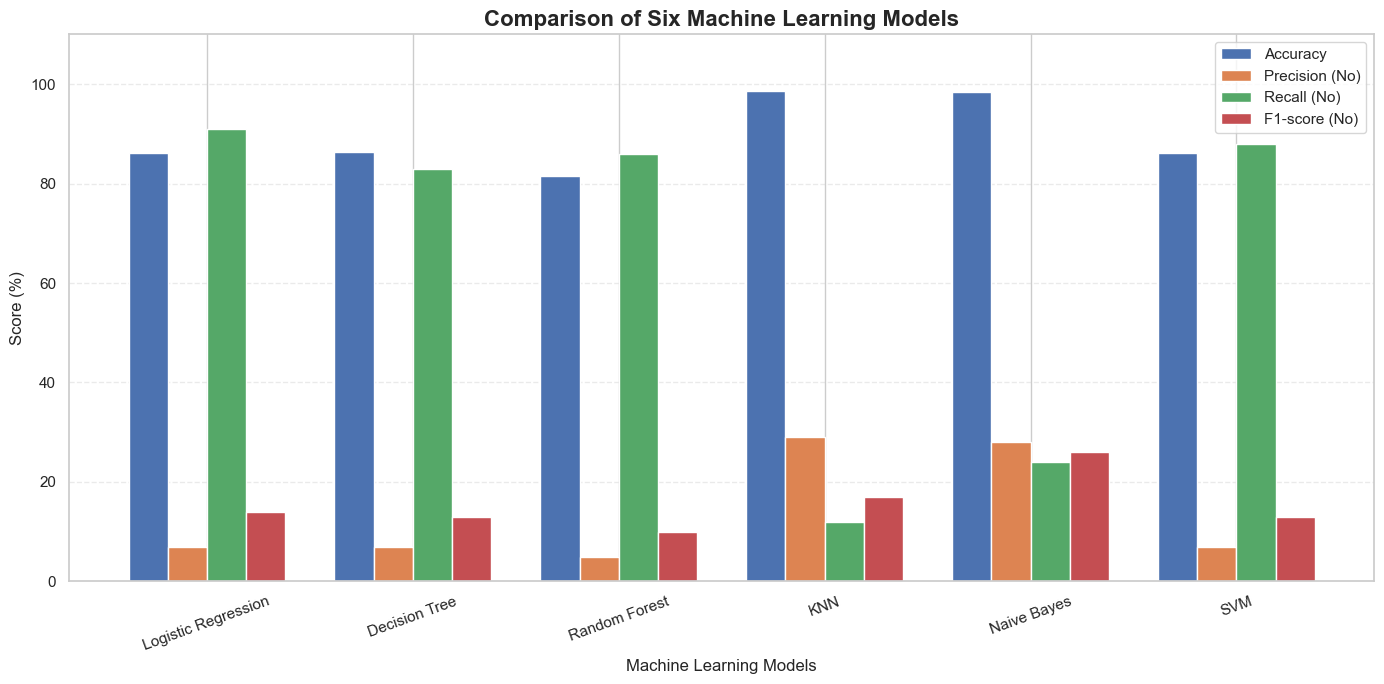

In [66]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Store model evaluation results
model_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'KNN',
        'Naive Bayes',
        'SVM'
    ],
    'Accuracy': [86.09, 86.26, 81.52, 98.57, 98.34, 86.05],
    'Precision (No)': [7, 7, 5, 29, 28, 7],
    'Recall (No)': [91, 83, 86, 12, 24, 88],
    'F1-score (No)': [14, 13, 10, 17, 26, 13]
})

print("MODEL PERFORMANCE COMPARISON")
display(model_results)

# Plot comparison
metrics = [
    'Accuracy',
    'Precision (No)',
    'Recall (No)',
    'F1-score (No)'
]

x = np.arange(len(model_results))
width = 0.19

plt.figure(figsize=(14, 7))

for i, metric in enumerate(metrics):
    plt.bar(
        x + (i - 1.5) * width,
        model_results[metric],
        width,
        label=metric
    )

plt.title('Comparison of Six Machine Learning Models',
          fontsize=16, fontweight='bold')

plt.xlabel('Machine Learning Models')
plt.ylabel('Score (%)')
plt.xticks(x, model_results['Model'], rotation=20)
plt.ylim(0, 110)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


In [67]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone

# Split the existing training data into training and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Create a fresh preprocessing configuration
validation_preprocessor = clone(preprocessor)

# Fit only on the smaller training set
X_subtrain_processed = validation_preprocessor.fit_transform(
    X_subtrain
)

# Transform validation data
X_val_processed = validation_preprocessor.transform(X_val)

print("Validation dataset created successfully!")

print("Training records:", X_subtrain.shape[0])
print("Validation records:", X_val.shape[0])
print("Training class distribution:")
print(y_subtrain.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())


Validation dataset created successfully!
Training records: 61198
Validation records: 15300
Training class distribution:
Timely response?
Yes    60452
No       746
Name: count, dtype: int64

Validation class distribution:
Timely response?
Yes    15113
No       187
Name: count, dtype: int64


In [68]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve
import numpy as np

# Train a fresh Logistic Regression model
lr_tuning_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

lr_tuning_model.fit(X_subtrain_processed, y_subtrain)

# Get probability of the minority class: No
no_index = list(lr_tuning_model.classes_).index('No')

val_probabilities = lr_tuning_model.predict_proba(
    X_val_processed
)[:, no_index]

# Convert validation target into binary values
y_val_binary = (y_val == 'No').astype(int)

# Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_val_binary,
    val_probabilities
)

# Calculate F1-score for each threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

# Find threshold with the highest validation F1-score
best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("THRESHOLD OPTIMIZATION RESULTS")
print("--------------------------------")
print("Best Threshold:", round(best_threshold, 4))
print("Validation Precision:", round(precision[best_index], 4))
print("Validation Recall:", round(recall[best_index], 4))
print("Validation F1-score:", round(f1_scores[best_index], 4))


THRESHOLD OPTIMIZATION RESULTS
--------------------------------
Best Threshold: 0.951
Validation Precision: 0.193
Validation Recall: 0.2941
Validation F1-score: 0.2331


In [69]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Get the probability of an untimely response (No)
no_index = list(lr_model.classes_).index('No')

test_probabilities = lr_model.predict_proba(
    X_test_processed
)[:, no_index]

# Apply the threshold selected using validation data
tuned_predictions = np.where(
    test_probabilities >= best_threshold,
    'No',
    'Yes'
)

# Evaluate the tuned model
print("TUNED LOGISTIC REGRESSION RESULTS")
print("---------------------------------")

print("Threshold:", round(best_threshold, 4))
print("Accuracy:", round(accuracy_score(y_test, tuned_predictions), 4))

print("\nClassification Report:")
print(classification_report(y_test, tuned_predictions))

print("Confusion Matrix:")
print(confusion_matrix(y_test, tuned_predictions, labels=['No', 'Yes']))


TUNED LOGISTIC REGRESSION RESULTS
---------------------------------
Threshold: 0.951
Accuracy: 0.9782

Classification Report:
              precision    recall  f1-score   support

          No       0.23      0.33      0.27       233
         Yes       0.99      0.99      0.99     18892

    accuracy                           0.98     19125
   macro avg       0.61      0.66      0.63     19125
weighted avg       0.98      0.98      0.98     19125

Confusion Matrix:
[[   77   156]
 [  260 18632]]


In [70]:

import pandas as pd

model_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'KNN',
        'Naive Bayes',
        'SVM',
        'Tuned Logistic Regression'
    ],
    'Accuracy (%)': [
        86.09, 86.26, 81.52, 98.57, 98.34, 86.05, 97.82
    ],
    'Precision No (%)': [
        7, 7, 5, 29, 28, 7, 23
    ],
    'Recall No (%)': [
        91, 83, 86, 12, 24, 88, 33
    ],
    'F1-score No (%)': [
        14, 13, 10, 17, 26, 13, 27
    ]
})

model_results = model_results.sort_values(
    by='F1-score No (%)',
    ascending=False
)

print("FINAL MODEL COMPARISON")
display(model_results)


FINAL MODEL COMPARISON


,Model,Accuracy (%),Precision No (%),Recall No (%),F1-score No (%)
6,Tuned Logistic Regression,97.82,23,33,27
4,Naive Bayes,98.34,28,24,26
3,KNN,98.57,29,12,17
0,Logistic Regression,86.09,7,91,14
1,Decision Tree,86.26,7,83,13
5,SVM,86.05,7,88,13
2,Random Forest,81.52,5,86,10


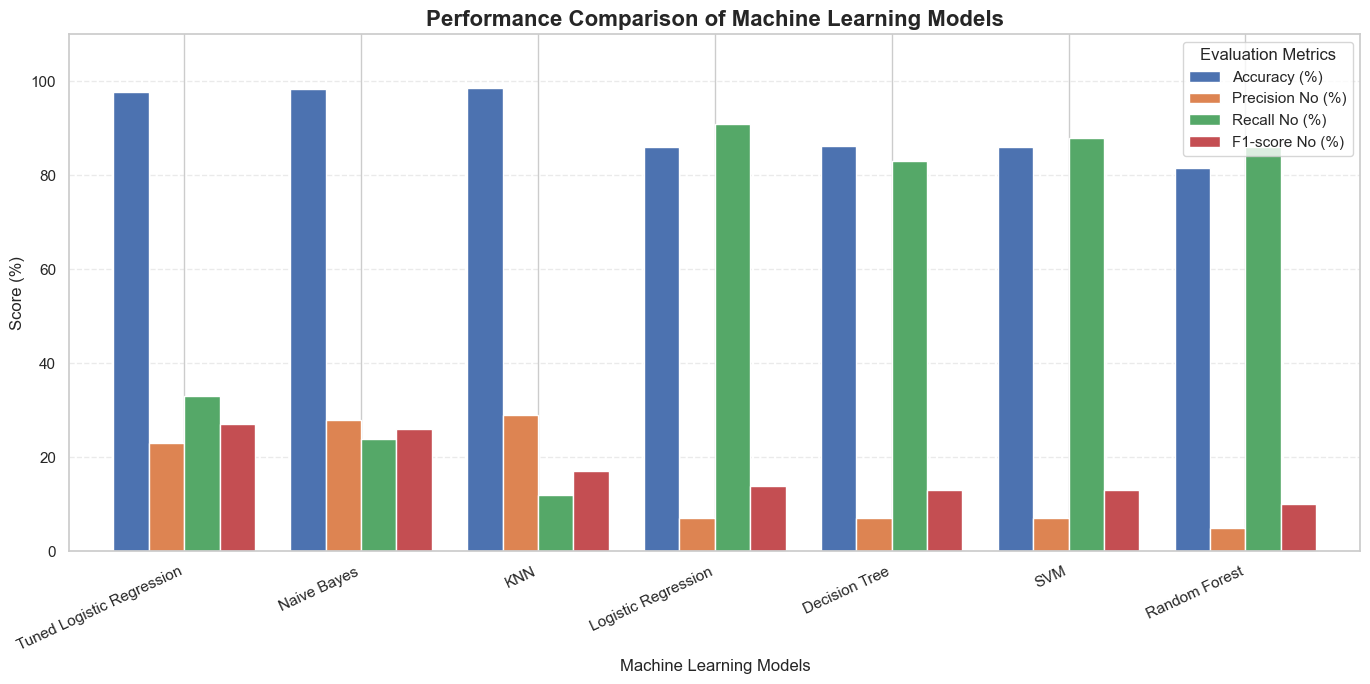

In [71]:

import matplotlib.pyplot as plt
import numpy as np

metrics = [
    'Accuracy (%)',
    'Precision No (%)',
    'Recall No (%)',
    'F1-score No (%)'
]

plot_data = model_results.set_index('Model')[metrics]

ax = plot_data.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

plt.title(
    'Performance Comparison of Machine Learning Models',
    fontsize=16,
    fontweight='bold'
)
plt.xlabel('Machine Learning Models', fontsize=12)
plt.ylabel('Score (%)', fontsize=12)
plt.xticks(rotation=25, ha='right')
plt.ylim(0, 110)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()


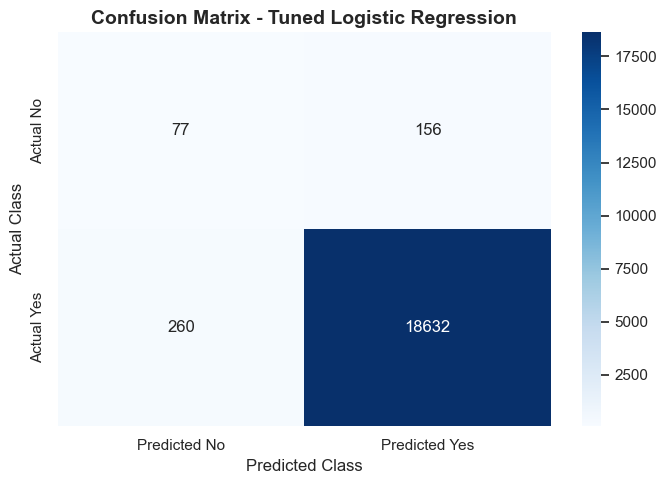

In [72]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    tuned_predictions,
    labels=['No', 'Yes']
)

# Plot confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Predicted No', 'Predicted Yes'],
    yticklabels=['Actual No', 'Actual Yes']
)

plt.title(
    'Confusion Matrix - Tuned Logistic Regression',
    fontsize=14,
    fontweight='bold'
)

plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')

plt.tight_layout()
plt.show()


In [73]:

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Convert sparse encoded data into a dense array
X_train_dense = X_train_processed.toarray()

# Standardize the encoded features for PCA
pca_scaler = StandardScaler()
X_train_scaled = pca_scaler.fit_transform(X_train_dense)

# Retain 95% of the total variance
pca = PCA(n_components=0.95, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)

print("PCA RESULTS")
print("-----------------------------")
print("Original number of features:", X_train_processed.shape[1])
print("Reduced number of components:", X_train_pca.shape[1])
print("Explained variance:", round(sum(pca.explained_variance_ratio_), 4))
print("Explained variance (%):", round(
    sum(pca.explained_variance_ratio_) * 100, 2
))


PCA RESULTS
-----------------------------
Original number of features: 570
Reduced number of components: 527
Explained variance: 0.9513
Explained variance (%): 95.13


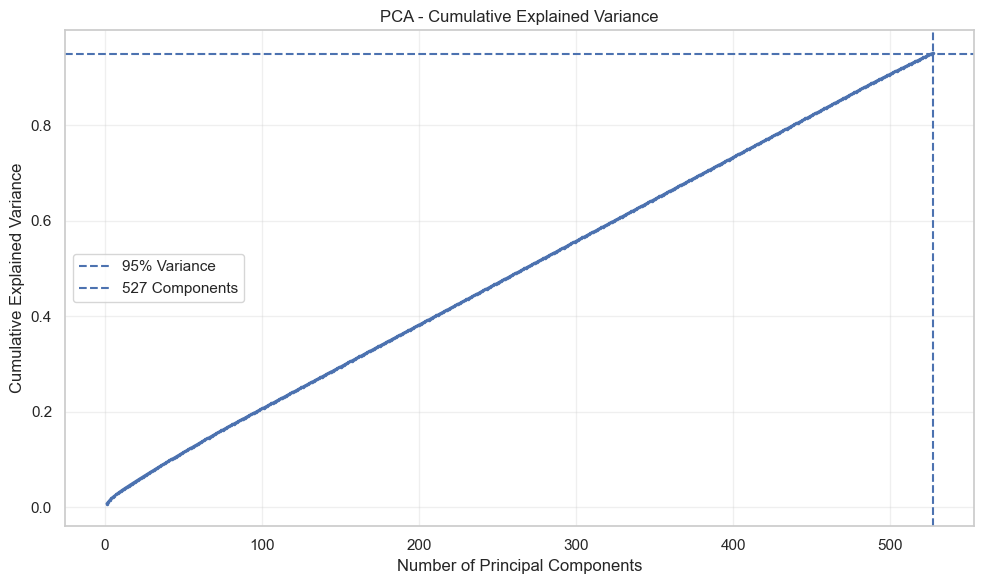

In [74]:

import matplotlib.pyplot as plt
import numpy as np

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(10, 6))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='.',
    markersize=3
)

plt.axhline(
    y=0.95,
    linestyle='--',
    label='95% Variance'
)

plt.axvline(
    x=X_train_pca.shape[1],
    linestyle='--',
    label='527 Components'
)

plt.title('PCA - Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
